68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Base FNN:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      2096
           1       0.94      0.88      0.91        58

    accuracy                           1.00      2154
   macro avg       0.97      0.94      0.95      2154
weighted avg       1.00      1.00      1.00      2154

68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
FNN + SMOTE:
               precision    recall  f1-score   support

           0       1.00      0.96      0.98      2096
           1       0.43      0.98      0.60        58

    accuracy                           0.96      2154
   macro avg       0.72      0.97      0.79      2154
weighted avg       0.98      0.96      0.97      2154

68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Ensemble 3xFNN:
               precision    recall  f1-score   support

           0       0.99      1.00      0.99      209

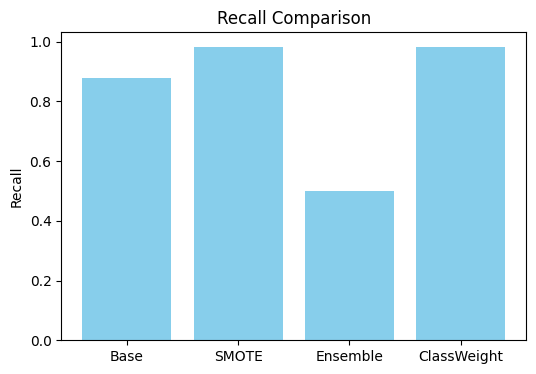

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, accuracy_score, recall_score

# Load clean static features
# Ensure train_data_features.csv contains precomputed features per event

df = pd.read_csv("../csv/train_data_features.csv")
X = df.drop(columns=["event_id", "risk"]).copy()
y = (df["risk"] >= -6).astype(int).values

# Handle infinities and NaNs
df_infs = X.replace([np.inf, -np.inf], np.nan)
X = df_infs.fillna(df_infs.median())

# Split into train and test
X_train, X_test, y_train, y_test = train_test_split(
    X.values, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# Scale features
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Build base FNN architecture
def build_fnn(input_dim, layers=[128,64,32], dropout_rates=[0.3,0.2,0.1]):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(layers[0], activation='relu'),
        Dropout(dropout_rates[0]),
        Dense(layers[1], activation='relu'),
        Dropout(dropout_rates[1]),
        Dense(layers[2], activation='relu'),
        Dropout(dropout_rates[2]),
        Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy','recall']
    )
    return model

# Early stopping callback
estop = EarlyStopping(patience=5, restore_best_weights=True)

# 1) Base FNN
base_fnn = build_fnn(X_train_scaled.shape[1])
history_base = base_fnn.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[estop],
    verbose=0
)
pred_base = (base_fnn.predict(X_test_scaled).ravel() > 0.5).astype(int)
print("Base FNN:\n", classification_report(y_test, pred_base))

# 2) FNN + SMOTE
sm = SMOTE(random_state=42)
X_sm, y_sm = sm.fit_resample(X_train_scaled, y_train)
smote_fnn = build_fnn(X_sm.shape[1])
history_sm = smote_fnn.fit(
    X_sm, y_sm,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[estop],
    verbose=0
)
pred_sm = (smote_fnn.predict(X_test_scaled).ravel() > 0.5).astype(int)
print("FNN + SMOTE:\n", classification_report(y_test, pred_sm))

# 3) Ensemble of 3 FNNs
ensemble_preds = []
for i in range(3):
    fnn_e = build_fnn(X_train_scaled.shape[1])
    fnn_e.fit(
        X_train_scaled, y_train,
        validation_split=0.2,
        epochs=30,
        batch_size=32,
        callbacks=[estop],
        verbose=0
    )
    ensemble_preds.append(fnn_e.predict(X_test_scaled).ravel())
avg_pred = np.mean(ensemble_preds, axis=0)
pred_ens = (avg_pred > 0.5).astype(int)
print("Ensemble 3xFNN:\n", classification_report(y_test, pred_ens))

# 4) FNN + class_weight
# compute class weights manually
total = len(y_train)
count_pos = np.sum(y_train)
count_neg = total - count_pos
class_weights = {0: 1.0, 1: count_neg/ count_pos}
w_fnn = build_fnn(X_train_scaled.shape[1])
history_w = w_fnn.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[estop],
    verbose=0
)
pred_w = (w_fnn.predict(X_test_scaled).ravel() > 0.5).astype(int)
print("FNN + class_weight:\n", classification_report(y_test, pred_w))

# Compare recall scores
methods = ['Base', 'SMOTE', 'Ensemble', 'ClassWeight']
recalls = [
    recall_score(y_test, pred_base),
    recall_score(y_test, pred_sm),
    recall_score(y_test, pred_ens),
    recall_score(y_test, pred_w)
]
plt.figure(figsize=(6,4))
plt.bar(methods, recalls, color='skyblue')
plt.ylabel('Recall')
plt.title('Recall Comparison')
plt.show()
